# 04 · Train & evaluate PLSR (per sensor location)

Port of `ProBallast_PLSR_02.m`. Builds the labelled table, fits one PLSR per
sensor location (A1, A2, A7, A11), and evaluates on the held-out day-range
test points with MAPE and correlation.

The model is swappable — `fit_per_location` works on a plain (X, y) table, so
XGBoost/LightGBM/CatBoost can drop in later.


In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, os.path.abspath('../src'))
import numpy as np, pandas as pd
from intelliswitch import Config, paths

# --- paths -----------------------------------------------------------------
# The project data lake (medallion tiers) is resolved by intelliswitch.paths, so
# it works regardless of the notebook's working dir and is overridable via the
# INTELLISWITCH_DATA_DIR / INTELLISWITCH_MODELS_DIR env vars.
RAW_CACHE = paths.RAW_CACHE       # data/interim/raw_cache  (decoded .npz, stage 1)
STORE     = paths.FEATURE_STORE   # data/processed/feature_store
MODELS    = paths.MODELS          # data/models
paths.ensure()                    # create the lake dirs if missing

# Raw source recordings (~7,800 logs) are large and live on the external drive;
# point DATA_ROOT at them, or symlink/copy the source into paths.RAW.
DATA_ROOT = Path(r"/Volumes/Seagate Expansion Drive/Mohammad/M Drive DTU/MATLAB Scripts/IntelliswitchScripts")
W10   = DATA_ROOT / "W10v140"       # vibration .log
BLADE = DATA_ROOT / "Bladenr8252"   # geometry .csv

cfg = Config()

## 1 · Build the labelled training table
Set `N` high (or `None`) to use the full log set. Extraction is ~2 s/log.


In [2]:
from pathlib import Path
from intelliswitch.features import extract_features
from intelliswitch.geometry import align_campaigns, build_deg_model
from intelliswitch.geometry.deg_model import attach_labels

deg = build_deg_model(align_campaigns(BLADE, cfg), cfg)

N = 300            # number of logs to process (None = all ~7800)
logs = sorted(Path(W10).glob('*.log'))
logs = logs if N is None else logs[:N]
frames = []
for i, p in enumerate(logs):
    r = extract_features(p, cfg)
    if r.accepted:
        frames.append(r.features)
    if (i+1) % 50 == 0:
        print(f'{i+1}/{len(logs)} logs, {sum(len(f) for f in frames)} rows')
data = pd.concat(frames, ignore_index=True)
data = attach_labels(data, deg, cfg)
data = data.dropna(subset=['y'])
print('labelled rows:', len(data))
data.groupby('sensor').size()


50/300 logs, 67 rows
100/300 logs, 126 rows
150/300 logs, 138 rows
200/300 logs, 160 rows
250/300 logs, 173 rows
300/300 logs, 176 rows
labelled rows: 176


sensor
A1     26
A11    92
A2     58
dtype: int64

## 2 · Optionally persist the table


In [3]:
# data.to_parquet(DATA / 'processed' / 'training_table.parquet')
data[['source','sensor','days','speed_kmh','y']].describe(include='all')


,source,sensor,days,speed_kmh,y
count,176,176,176.000000,176.000000,176.000000
unique,48,3,NaN,NaN,NaN
top,160726_234622.log,A11,NaN,NaN,NaN
freq,13,92,NaN,NaN,NaN
mean,NaN,NaN,-889.295455,137.266647,-1.505496
std,NaN,NaN,8.625754,12.809449,0.411285
min,NaN,NaN,-901.000000,121.957229,-1.842406
25%,NaN,NaN,-898.000000,125.053685,-1.841230
50%,NaN,NaN,-890.000000,132.996588,-1.839573
75%,NaN,NaN,-884.000000,148.021889,-0.932727


## 3 · Fit one PLSR per location and evaluate


In [4]:
from intelliswitch.model import fit_per_location

results = fit_per_location(data, cfg)
summary = []
for name, r in results.items():
    if r['model'] is None:
        summary.append(dict(sensor=name, error=r.get('error'))); continue
    m, e = r['model'], r['eval']
    summary.append(dict(sensor=name, NOC=m.n_components, n_train=m.n_train,
                        train_R2=round(m.train_r2,3),
                        test_pts=e['n_testpoints'],
                        MAPE=round(e['mape'],1), corr=round(e['corr'],3)))
pd.DataFrame(summary)


,sensor,error
0,A1,too few training rows (0) for 'A1'
1,A2,too few training rows (0) for 'A2'
2,A11,too few training rows (0) for 'A11'


## 4 · Predicted vs. reference quality at the test points


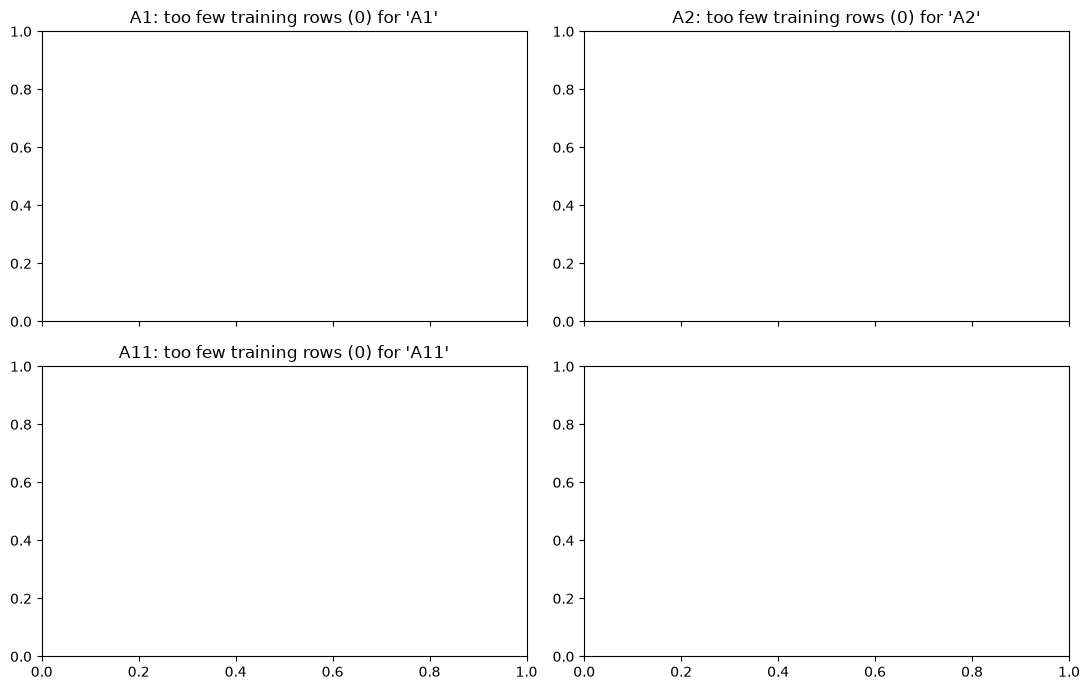

In [5]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (name, r) in zip(axes.ravel(), results.items()):
    if r['model'] is None: ax.set_title(f'{name}: {r.get("error")}'); continue
    e = r['eval']
    ax.plot(e['mid_days'], e['ref'],  '--o', label='reference (geometry)')
    ax.plot(e['mid_days'], e['pred'], '-d',  label='PLSR estimate')
    ax.set_title(f"{name}  MAPE={e['mape']:.1f}%  corr={e['corr']:.2f}")
    ax.set_xlabel('days before 2019-01-01'); ax.grid(True); ax.legend()
plt.tight_layout(); plt.show()
